# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [2]:
import string
import nltk
from nltk.corpus import gutenberg

# Descargar recursos necesarios de NLTK
nltk.download('gutenberg')
nltk.download('punkt')

# 1. Cargar textos originales e identificar identificadores
file_ids = gutenberg.fileids()

print(f"Número total de documentos: {len(file_ids)}\n")
print(f"{'ID Documento':<35} | {'Caracteres':<12} | {'Palabras orig.':<12}")
print("-" * 65)

corpus_raw = {}
for fid in file_ids:
    text = gutenberg.raw(fid)
    corpus_raw[fid] = text
    words_count = len(gutenberg.words(fid))
    print(f"{fid:<35} | {len(text):<12,} | {words_count:<12,}")

# 3. Implementación y configuración de Tokenización y Normalización
def preprocess_text(text):
    # Conversión a minúsculas
    text_lower = text.lower()
    # Eliminación de puntuación
    translator = str.maketrans('', '', string.punctuation)
    text_clean = text_lower.translate(translator)
    # Tokenización simple por espacio
    tokens = text_clean.split()
    return tokens

# Procesar todo el corpus
corpus_tokens = {fid: preprocess_text(text) for fid, text in corpus_raw.items()}

# Ejemplo de verificación en el primer documento
first_id = file_ids[0]
print(f"\nEjemplo de preprocesamiento para '{first_id}':")
print(f"Muestra de tokens: {corpus_tokens[first_id][:15]}")

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\LiamZM\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LiamZM\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\LiamZM\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Número total de documentos: 18

ID Documento                        | Caracteres   | Palabras orig.
-----------------------------------------------------------------
austen-emma.txt                     | 887,071      | 192,427     
austen-persuasion.txt               | 466,292      | 98,171      
austen-sense.txt                    | 673,022      | 141,576     
bible-kjv.txt                       | 4,332,554    | 1,010,654   
blake-poems.txt                     | 38,153       | 8,354       
bryant-stories.txt                  | 249,439      | 55,563      
burgess-busterbrown.txt             | 84,663       | 18,963      
carroll-alice.txt                   | 144,395      | 34,110      
chesterton-ball.txt                 | 457,450      | 96,996      
chesterton-brown.txt                | 406,629      | 86,063      
chesterton-thursday.txt             | 320,525      | 69,213      
edgeworth-parents.txt               | 935,158      | 210,663     
melville-moby_dick.txt              | 1,24

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [3]:
def sequential_search(query_term, corpus):
    # Normalizar el término de búsqueda con la misma lógica
    term = query_term.lower().strip()
    matching_docs = []

    # Lazo 1: Recorre los documentos del corpus
    for doc_id, tokens in corpus.items():
        # Lazo 2: Recorre los tokens del documento actual
        for token in tokens:
            if token == term:
                matching_docs.append(doc_id)
                break  # Encontrado en este documento, pasamos al siguiente doc_id

    return matching_docs

# --- Pruebas con distintos tipos de términos ---

# Término frecuente (palabra común)
query_frequent = "the"
res_frequent = sequential_search(query_frequent, corpus_tokens)

# Término poco frecuente (específico)
query_rare = "whale"
res_rare = sequential_search(query_rare, corpus_tokens)

# Término inexistente
query_nonexistent = "cyberpunk"
res_nonexistent = sequential_search(query_nonexistent, corpus_tokens)

print(f"Búsqueda secuencial para '{query_frequent}' (frecuente):")
print(f"-> Encontrado en {len(res_frequent)} documentos: {res_frequent}\n")

print(f"Búsqueda secuencial para '{query_rare}' (poco frecuente):")
print(f"-> Encontrado en {len(res_rare)} documentos: {res_rare}\n")

print(f"Búsqueda secuencial para '{query_nonexistent}' (inexistente):")
print(f"-> Encontrado en {len(res_nonexistent)} documentos: {res_nonexistent}")

Búsqueda secuencial para 'the' (frecuente):
-> Encontrado en 18 documentos: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Búsqueda secuencial para 'whale' (poco frecuente):
-> Encontrado en 6 documentos: ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']

Búsqueda secuencial para 'cyberpunk' (inexistente):
-> Encontrado en 0 documentos: []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [4]:
import time

def measure_sequential_time(query_term, corpus, runs=30):
    times_ns = []
    
    for _ in range(runs):
        start_time = time.perf_counter_ns()
        matching_docs = sequential_search(query_term, corpus)
        end_time = time.perf_counter_ns()
        
        times_ns.append(end_time - start_time)
    
    # Media aritmética en nanosegundos convertida a milisegundos (1 ms = 1,000,000 ns)
    avg_time_ms = (sum(times_ns) / runs) / 1_000_000
    return matching_docs, avg_time_ms

# Probar medición para los tres tipos de términos (30 ejecuciones cada uno)
terms_to_test = {
    "Frecuente": "the",
    "Poco frecuente": "whale",
    "Inexistente": "cyberpunk"
}

print(f"{'Categoría':<15} | {'Término':<12} | {'Tiempo Medio (ms)':<18} | {'Documentos':<10}")
print("-" * 62)

for category, term in terms_to_test.items():
    docs, avg_ms = measure_sequential_time(term, corpus_tokens, runs=30)
    print(f"{category:<15} | {term:<12} | {avg_ms:<18.4f} | {len(docs):<10}")

Categoría       | Término      | Tiempo Medio (ms)  | Documentos
--------------------------------------------------------------
Frecuente       | the          | 0.0176             | 18        
Poco frecuente  | whale        | 38.5164            | 6         
Inexistente     | cyberpunk    | 57.6242            | 0         


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [5]:
from collections import defaultdict

class InvertedIndex:
    def __init__(self):
        # Mapea término -> conjunto de doc_ids (postings)
        self.index = defaultdict(set)
        self.all_doc_ids = set()

    def build_index(self, corpus):
        """Construye el índice invertido a partir del corpus de tokens."""
        self.index.clear()
        self.all_doc_ids = set(corpus.keys())
        
        for doc_id, tokens in corpus.items():
            for token in tokens:
                self.index[token].add(doc_id)

    def get_postings(self, term):
        """Devuelve el conjunto de doc_ids donde aparece el término."""
        term_clean = term.lower().strip()
        return self.index.get(term_clean, set())

    def get_document_frequency(self, term):
        """Devuelve la Frecuencia Documental (DF) de un término."""
        return len(self.get_postings(term))

    # --- Consultas Booleanas ---
    
    def query_single(self, term):
        """Consulta de un solo término."""
        return sorted(list(self.get_postings(term)))

    def query_and(self, term1, term2):
        """Consulta booleana AND: intersección de postings."""
        p1 = self.get_postings(term1)
        p2 = self.get_postings(term2)
        return sorted(list(p1.intersection(p2)))

    def query_or(self, term1, term2):
        """Consulta booleana OR: unión de postings."""
        p1 = self.get_postings(term1)
        p2 = self.get_postings(term2)
        return sorted(list(p1.union(p2)))

    def query_not(self, term):
        """Consulta booleana NOT: complemento de postings con respecto a la colección."""
        p = self.get_postings(term)
        return sorted(list(self.all_doc_ids.difference(p)))


# 1. Construir el índice
inverted_idx = InvertedIndex()
inverted_idx.build_index(corpus_tokens)

print(f"Tamaño del vocabulario del índice: {len(inverted_idx.index)} términos únicos.\n")

# 2. Inspección de postings y Frecuencia Documental (DF)
test_terms = ["the", "whale", "cyberpunk", "love", "blood"]

print(f"{'Término':<15} | {'DF (Frec. Documental)':<22} | {'Lista de Postings (Muestra)':<30}")
print("-" * 75)
for t in test_terms:
    postings = inverted_idx.query_single(t)
    df = inverted_idx.get_document_frequency(t)
    sample_postings = str(postings[:3]) + ("..." if len(postings) > 3 else "")
    print(f"{t:<15} | {df:<22} | {sample_postings:<30}")

# 3. Ejemplos de consultas booleanas
print("\n--- Pruebas de Consultas Booleanas ---")

# AND
q_and = inverted_idx.query_and("whale", "sea")
print(f"1. 'whale AND sea' ({len(q_and)} docs): {q_and}")

# OR
q_or = inverted_idx.query_or("austen", "chesterton")
print(f"2. 'austen OR chesterton' ({len(q_or)} docs): {q_or}")

# NOT
q_not = inverted_idx.query_not("the")
print(f"3. 'NOT the' ({len(q_not)} docs): {q_not}")

Tamaño del vocabulario del índice: 57369 términos únicos.

Término         | DF (Frec. Documental)  | Lista de Postings (Muestra)   
---------------------------------------------------------------------------
the             | 18                     | ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt']...
whale           | 6                      | ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt']...
cyberpunk       | 0                      | []                            
love            | 15                     | ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt']...
blood           | 16                     | ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt']...

--- Pruebas de Consultas Booleanas ---
1. 'whale AND sea' (6 docs): ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
2. 'austen OR chesterton' (6 docs): ['austen-emma.txt', 'austen-persu

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [7]:
import time

def measure_index_time(inverted_index, query_term, runs=30):
    times_ns = []
    
    for _ in range(runs):
        start_time = time.perf_counter_ns()
        matching_docs = inverted_index.query_single(query_term)
        end_time = time.perf_counter_ns()
        times_ns.append(end_time - start_time)
        
    avg_time_ms = (sum(times_ns) / runs) / 1_000_000
    return matching_docs, avg_time_ms

# Términos a evaluar en la comparación
test_queries = ["the", "whale", "cyberpunk", "love", "blood"]

print(f"{'Término':<12} | {'Igualdad Exacta':<16} | {'Secuencial (ms)':<18} | {'Índice (ms)':<15} | {'Aceleración (Speedup)':<22}")
print("-" * 90)

for term in test_queries:
    # Búsqueda secuencial
    docs_seq, time_seq = measure_sequential_time(term, corpus_tokens, runs=30)
    
    # Búsqueda indexada
    docs_idx, time_idx = measure_index_time(inverted_idx, term, runs=30)
    
    # Comprobar igualdad de resultados
    are_equal = (sorted(docs_seq) == sorted(docs_idx))
    
    # Cálculo de la mejora relativa (Speedup)
    speedup = (time_seq / time_idx) if time_idx > 0 else float('inf')
    
    print(f"{term:<12} | {str(are_equal):<16} | {time_seq:<18.5f} | {time_idx:<15.5f} | {speedup:<22.2f}x")

Término      | Igualdad Exacta  | Secuencial (ms)    | Índice (ms)     | Aceleración (Speedup) 
------------------------------------------------------------------------------------------
the          | True             | 0.00514            | 0.00103         | 4.99                  x
whale        | True             | 16.30789           | 0.00081         | 20133.20              x
cyberpunk    | True             | 24.27046           | 0.00058         | 41845.63              x
love         | True             | 1.79785            | 0.00093         | 1926.26               x
blood        | True             | 2.25960            | 0.00104         | 2172.69               x


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [8]:
import os
import re

# Ruta del directorio
dataset_path = r"C:\Users\LiamZM\Documents\RECUPERACION_INFORMACION\ir26b\data\txt-files\cache\epub"

def discover_gutenberg_files(base_path):
    valid_files = {}
    
    for root, dirs, files in os.walk(base_path):
        for file in files:
            # Seleccionar únicamente archivos .txt
            if file.endswith('.txt'):
                full_path = os.path.join(root, file)
                
                # Omitir archivos de licencia, indices o metadatos comunes si los hubiera
                if "readme" in file.lower() or "license" in file.lower():
                    continue

                # Extraer el ID numérico del libro desde el nombre del archivo o carpeta
                # Los archivos suelen nombrarse como 'pg12345.txt' o '12345.txt'
                match = re.search(r'(\d+)', file)
                if match:
                    book_id = match.group(1)
                    
                    # Si el libro no está registrado, se guarda su ruta
                    if book_id not in valid_files:
                        valid_files[book_id] = full_path
                else:
                    # Si no contiene número, usar la ruta relativa como identificador
                    rel_path = os.path.relpath(full_path, base_path)
                    valid_files[rel_path] = full_path

    return valid_files

# Ejecutar el escaneo del directorio
gutenberg_large_corpus = discover_gutenberg_files(dataset_path)

print(f"Búsqueda finalizada.")
print(f"Número total de documentos únicos válidos identificados: {len(gutenberg_large_corpus):,}")

# Mostrar una muestra de los primeros 5 documentos identificados
sample_ids = list(gutenberg_large_corpus.keys())[:5]
print("\nMuestra de documentos identificados:")
for b_id in sample_ids:
    print(f"ID: {b_id} -> {gutenberg_large_corpus[b_id]}")

Búsqueda finalizada.
Número total de documentos únicos válidos identificados: 78,145

Muestra de documentos identificados:
ID: 1 -> C:\Users\LiamZM\Documents\RECUPERACION_INFORMACION\ir26b\data\txt-files\cache\epub\1\pg1.txt
ID: 10 -> C:\Users\LiamZM\Documents\RECUPERACION_INFORMACION\ir26b\data\txt-files\cache\epub\10\pg10.txt
ID: 100 -> C:\Users\LiamZM\Documents\RECUPERACION_INFORMACION\ir26b\data\txt-files\cache\epub\100\pg100.txt
ID: 1000 -> C:\Users\LiamZM\Documents\RECUPERACION_INFORMACION\ir26b\data\txt-files\cache\epub\1000\pg1000.txt
ID: 10000 -> C:\Users\LiamZM\Documents\RECUPERACION_INFORMACION\ir26b\data\txt-files\cache\epub\10000\pg10000.txt


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [9]:
import sys

# 1. Seleccionar un subconjunto del corpus grande (ej. primeros 500 documentos)
SUBSET_SIZE = 500
subset_keys = list(gutenberg_large_corpus.keys())[:SUBSET_SIZE]

print(f"Cargando y procesando un subconjunto de {SUBSET_SIZE} documentos...")

# 2. Cargar y tokenizar los documentos manteniendo sus IDs originales
corpus_large_tokens = {}
for doc_id in subset_keys:
    file_path = gutenberg_large_corpus[doc_id]
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            text = f.read()
            corpus_large_tokens[doc_id] = preprocess_text(text)
    except Exception as e:
        continue

total_tokens_count = sum(len(tokens) for tokens in corpus_large_tokens.values())
print(f"Subconjunto procesado correctamente.")
print(f"- Documentos válidos cargados: {len(corpus_large_tokens)}")
print(f"- Total de tokens en el subconjunto: {total_tokens_count:,}")

# Estimación básica de uso de memoria RAM del corpus tokenizado en bytes
memory_usage_mb = sys.getsizeof(corpus_large_tokens) / (1024 * 1024)
print(f"- Uso de memoria aprox. del diccionario tokenizado: {memory_usage_mb:.2f} MB\n")

# 3. Construir el índice invertido para el subconjunto
inverted_idx_large = InvertedIndex()
start_build = time.perf_counter_ns()
inverted_idx_large.build_index(corpus_large_tokens)
end_build = time.perf_counter_ns()

build_time_ms = (end_build - start_build) / 1_000_000
print(f"Índice Invertido construido en {build_time_ms:.2f} ms.")
print(f"Tamaño del vocabulario: {len(inverted_idx_large.index):,} términos únicos.\n")

# 4. Comparación de búsquedas y tiempos (30 ejecuciones por método)
test_queries_large = ["the", "water", "cyberpunk", "science", "freedom"]

print(f"{'Término':<12} | {'Igualdad Exacta':<16} | {'Secuencial (ms)':<18} | {'Índice (ms)':<15} | {'Aceleración (Speedup)':<22}")
print("-" * 90)

for term in test_queries_large:
    # Búsqueda secuencial
    docs_seq, time_seq = measure_sequential_time(term, corpus_large_tokens, runs=30)
    
    # Búsqueda indexada
    docs_idx, time_idx = measure_index_time(inverted_idx_large, term, runs=30)
    
    # Comprobar igualdad de resultados
    are_equal = (sorted(docs_seq) == sorted(docs_idx))
    
    # Aceleración
    speedup = (time_seq / time_idx) if time_idx > 0 else float('inf')
    
    print(f"{term:<12} | {str(are_equal):<16} | {time_seq:<18.5f} | {time_idx:<15.5f} | {speedup:<22.2f}x")

Cargando y procesando un subconjunto de 500 documentos...
Subconjunto procesado correctamente.
- Documentos válidos cargados: 500
- Total de tokens en el subconjunto: 35,645,128
- Uso de memoria aprox. del diccionario tokenizado: 0.01 MB

Índice Invertido construido en 4810.66 ms.
Tamaño del vocabulario: 615,623 términos únicos.

Término      | Igualdad Exacta  | Secuencial (ms)    | Índice (ms)     | Aceleración (Speedup) 
------------------------------------------------------------------------------------------
the          | True             | 0.03206            | 0.03158         | 1.02                  x
water        | True             | 77.32954           | 0.02394         | 3230.14               x
cyberpunk    | True             | 417.32217          | 0.00070         | 596174.52             x
science      | True             | 222.28568          | 0.01154         | 19267.76              x
freedom      | True             | 177.10038          | 0.01547         | 11445.52            

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Iniciando experimento de escalabilidad para el término 'water'...

n (Docs)   | Tokens Totales  | Secuencial (ms)    | Índice (ms)    
-----------------------------------------------------------------
50         | 4,061,616       | 4.8016             | 0.0020         
100        | 7,228,026       | 13.1913            | 0.0038         
250        | 18,924,476      | 41.4507            | 0.0097         
500        | 35,645,128      | 81.6015            | 0.0277         
1000       | 71,278,349      | 223.0719           | 0.0799         


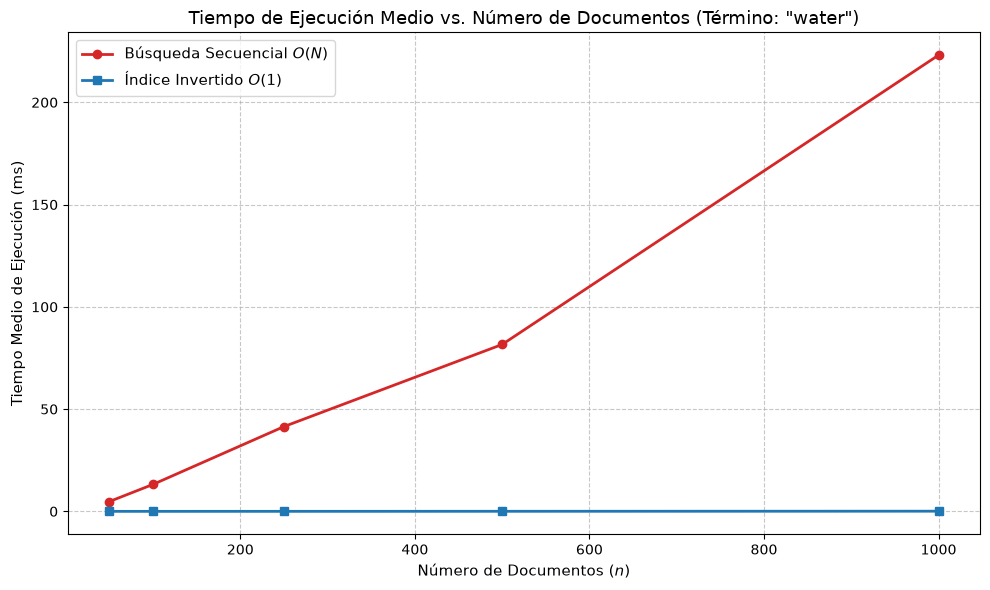

In [10]:
import matplotlib.pyplot as plt

# 1. Definir los tamaños crecientes del corpus y término de prueba
corpus_sizes = [50, 100, 250, 500, 1000]
target_term = "water"

# Estructuras para almacenar los datos del experimento
doc_counts = []
total_tokens_list = []
times_seq = []
times_idx = []

print(f"Iniciando experimento de escalabilidad para el término '{target_term}'...\n")
print(f"{'n (Docs)':<10} | {'Tokens Totales':<15} | {'Secuencial (ms)':<18} | {'Índice (ms)':<15}")
print("-" * 65)

for n in corpus_sizes:
    # Obtener las claves del subconjunto
    subset_keys = list(gutenberg_large_corpus.keys())[:n]
    
    # Cargar y tokenizar los documentos de este subconjunto
    subset_tokens = {}
    for doc_id in subset_keys:
        file_path = gutenberg_large_corpus[doc_id]
        try:
            with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
                subset_tokens[doc_id] = preprocess_text(f.read())
        except Exception:
            continue
            
    if not subset_tokens:
        continue

    # 5. Registrar total de tokens
    total_tokens = sum(len(t) for t in subset_tokens.values())
    
    # 1 y 2. Búsqueda secuencial (30 ejecuciones)
    _, seq_ms = measure_sequential_time(target_term, subset_tokens, runs=30)
    
    # 3. Construir índice invertido para este subconjunto
    sub_index = InvertedIndex()
    sub_index.build_index(subset_tokens)
    
    # 4. Búsqueda indexada (30 ejecuciones)
    _, idx_ms = measure_index_time(sub_index, target_term, runs=30)
    
    # Almacenar métricas
    actual_n = len(subset_tokens)
    doc_counts.append(actual_n)
    total_tokens_list.append(total_tokens)
    times_seq.append(seq_ms)
    times_idx.append(idx_ms)
    
    print(f"{actual_n:<10} | {total_tokens:<15,} | {seq_ms:<18.4f} | {idx_ms:<15.4f}")

# Gráfica de Escalabilidad
plt.figure(figsize=(10, 6))
plt.plot(doc_counts, times_seq, marker='o', linewidth=2, label='Búsqueda Secuencial $O(N)$', color='tab:red')
plt.plot(doc_counts, times_idx, marker='s', linewidth=2, label='Índice Invertido $O(1)$', color='tab:blue')

plt.title(f'Tiempo de Ejecución Medio vs. Número de Documentos (Término: "{target_term}")', fontsize=13)
plt.xlabel('Número de Documentos ($n$)', fontsize=11)
plt.ylabel('Tiempo Medio de Ejecución (ms)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

=== RESULTADOS DEL AJUSTE LINEAL POR MÍNIMOS CUADRADOS ===
1. Búsqueda Secuencial:
   Ecuación: t(n) = 0.227911 * n + (-13.782629)
   Coeficiente R²: 0.9844

2. Índice Invertido:
   Ecuación: t(n) = 0.000083 * n + (-0.006784)
   Coeficiente R²: 0.9745



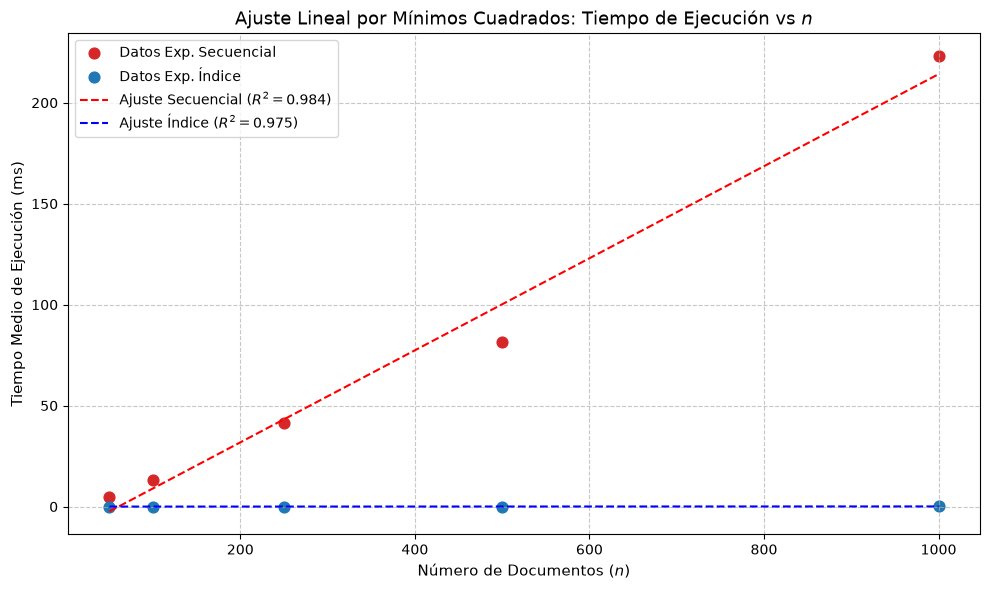

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Convertir listas a arrays de NumPy
X = np.array(doc_counts)
y_seq = np.array(times_seq)
y_idx = np.array(times_idx)

# 1. Ajuste lineal por mínimos cuadrados (Polinomio de grado 1)
# y = a*x + b
a_seq, b_seq = np.polyfit(X, y_seq, 1)
a_idx, b_idx = np.polyfit(X, y_idx, 1)

# Función para calcular R^2 (Coeficiente de determinación)
def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot) if ss_tot != 0 else 1.0

# Valores predichos
pred_seq = a_seq * X + b_seq
pred_idx = a_idx * X + b_idx

r2_seq = calculate_r2(y_seq, pred_seq)
r2_idx = calculate_r2(y_idx, pred_idx)

# Imprimir resultados del ajuste
print("=== RESULTADOS DEL AJUSTE LINEAL POR MÍNIMOS CUADRADOS ===")
print(f"1. Búsqueda Secuencial:")
print(f"   Ecuación: t(n) = {a_seq:.6f} * n + ({b_seq:.6f})")
print(f"   Coeficiente R²: {r2_seq:.4f}\n")

print(f"2. Índice Invertido:")
print(f"   Ecuación: t(n) = {a_idx:.6f} * n + ({b_idx:.6f})")
print(f"   Coeficiente R²: {r2_idx:.4f}\n")

# --- Visualización de los datos experimentales y las funciones ajustadas ---
plt.figure(figsize=(10, 6))

# Datos experimentales (Puntos)
plt.scatter(X, y_seq, color='tab:red', s=60, label='Datos Exp. Secuencial')
plt.scatter(X, y_idx, color='tab:blue', s=60, label='Datos Exp. Índice')

# Rectas ajustadas (Líneas discontinuas)
X_line = np.linspace(min(X), max(X), 100)
plt.plot(X_line, a_seq * X_line + b_seq, 'r--', label=f'Ajuste Secuencial ($R^2={r2_seq:.3f}$)')
plt.plot(X_line, a_idx * X_line + b_idx, 'b--', label=f'Ajuste Índice ($R^2={r2_idx:.3f}$)')

plt.title('Ajuste Lineal por Mínimos Cuadrados: Tiempo de Ejecución vs $n$', fontsize=13)
plt.xlabel('Número de Documentos ($n$)', fontsize=11)
plt.ylabel('Tiempo Medio de Ejecución (ms)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# Análisis
En busqueda secuencial, el modelo lineal representa casi perfectamente el comportamiento del algoritmo R^2 = 0.98, y la pendiente positiva valida experimentalmente su complejidad teórica O (N*L), además, el tiempo de respuesta crece de forma directamente proporcional al número de documentos.

En cambio, en el indice invertido la pendiente es prácticamente nula, por lo que el tiempo se mantiene constante sin importar el tamaño del corpus, gracias a que su complejidad es O(1)